In [86]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [139]:
import matplotlib.pyplot as plt 
from matplotlib.patches import Rectangle 

In [140]:
  # STEP 1: OUR EXAMPLE MARKET DATA
opens = [98,101,108,113] 

In [141]:
highs = [105,110,115,120]

In [142]:
lows = [95,100,105,110]

In [143]:
closes = [100,106,112,118]

In [144]:
volumes = [200,300,400,500]

In [145]:
total_typical = 0

In [146]:
total_volume = 0

In [147]:
vwap_values = []

In [148]:
for high,low,close,volume in zip(highs,lows,closes,volumes):
    typical_price = (high+low+close) / 3
    total_typical_volumes = typical_price * volume
    total_typical = total_typical + total_typical_volumes 
    total_volume = total_volume + volume 
    vwap = total_typical / total_volume 
    vwap_values.append(vwap)
    
        
        
        
        

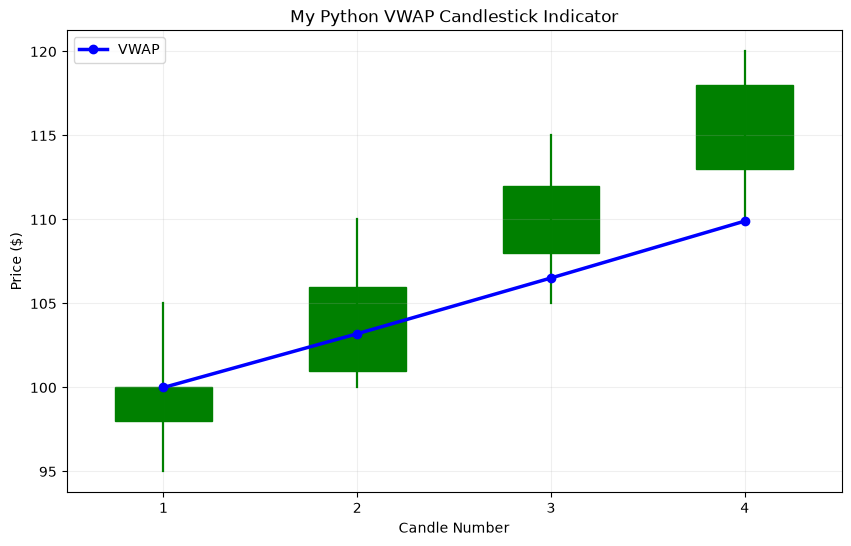

In [159]:
fig, ax = plt.subplots(figsize=(10,6))
# "plt.subplots()" creates the figure and its plotting area.
# "fig" stores the Figure object: the overall canvas.
# "ax" stores the Axes object: where we draw chart elements.
# STEP 3: CREATE THE CHART
#STEP 4: DRAW EACH CANDLESTICK
candle_numbers = list(range(1, len(opens)+1 ))
# This creates the horizontal positions for our candles.
# "len(opens)" counts how many opening prices we have: 4.
# "+ 1" gives us 5 because range() excludes its stop value.
# "range(1, 5)" generates the numbers 1, 2, 3, 4.
# "1" is our chosen starting candle number.
# "list()" converts that range into an actual list.
# "candle_numbers" becomes [1, 2, 3, 4].
# These represent positions along the x-axis, NOT stock prices.
# We chose to start at 1 because it's intuitive to number candles
# first, second, third, fourth. Starting at 0 would also work.
    # STEP 4: DRAW EACH CANDLESTICK
for x, o, h,l,c in zip(candle_numbers,opens,highs,lows,closes):
 # highs, lows, and closes are lists containing prices for ALL candles.
# high, low, and close represent ONE candle's prices at a time.
# The for loop goes through each candle individually.
# We use plural names for the lists and singular names for individual values.
    color = "green" if c>=o else "red"
            # This is a conditional expression.
    # "c >= o" asks: is the close greater than or equal to the open?
    # ">=" means "greater than or equal to."
    # If True, Python assigns the text "green" to color.
    # Otherwise, Python assigns the text "red".
    # We use quotation marks because these are strings (text).
    # For candle 1: 100 >= 98 is True, so color="green".
    # Note: an equal open and close is colored green by our choice. 
      # STEP 4A: DRAW THE WICK
    ax.plot([x, x], [l, h], color=color, linewidth=1.6)
    
# [x, x] means both points have the same horizontal position,
# so the line stays at one candle and becomes vertical.
# [l, h] means the line goes from the candle's low price
# up to the candle's high price.
# Matplotlib connects the two points (x, l) and (x, h).
# color=color makes the wick green or red depending on the candle.
# linewidth=1.6 controls how thick the wick looks.
    #Why do we repeat x twice? Because we want both points to be at the same horizontal position. That means:
#- point 1 is at x = 1
#- point 2 is also at x = 1
#If both x-values are the same, the line goes straight up and down.
#so essentilly the high and low price are diffrent points that we want at the same x value thats why its [x,x]
#That is why the wick is vertical. 
     # STEP 4B: CALCULATE THE CANDLE BODY'S HEIGHT
    body_height = max(abs(c-o),0.08)
  # STEP 1: Understand what body_height means.
# body_height is the height of the rectangular part of a candlestick.
# The rectangle represents the difference between the opening
# price (o) and the closing price (c).

# For example:
# o = 98
# c = 100
# The difference is 100 - 98 = 2.
# Therefore, the candle's body is $2 tall.
#
# STEP 2: Why do we use abs(c - o)?
# abs() is a Python function that returns the absolute value.
# This means it converts a negative number into a positive number.
#
# Example 1: Bullish (green) candle
# o = 98
# c = 100
# c - o = 100 - 98 = 2
# abs(2) = 2
#
# Example 2: Bearish (red) candle
# o = 100
# c = 98
# c - o = 98 - 100 = -2
# abs(-2) = 2
#
# Even though the second candle moved DOWN by $2,
# the rectangle still needs to be 2 units tall.
# Nonnegative means zero or greater.
# The negative sign tells us the direction of the price movement,
# NOT how tall the rectangle should be.
#
# STEP 3: Why do we use 0.08?
# 0.08 is the minimum height we allow when DRAWING the candle body.
# Since our chart uses dollar prices, 0.08 represents $0.08 (8 cents).
#
# Imagine:
# o = 100
# c = 100
# abs(100 - 100) = 0
#
# The opening and closing prices are identical.
# This is called a doji candle.
# If the rectangle has a height of 0, its body may be invisible.
# Therefore, we use 0.08 to make a very small body visible.
#
# IMPORTANT:
# The 0.08 is only used for displaying the candlestick.
# It does NOT change the real opening or closing prices.
# It does NOT affect our VWAP calculation.
#
# STEP 4: What does max() do?
# max() is a Python function that selects the LARGEST number.
#
# Example 1:
# max(2, 0.08) = 2
# Python chooses 2 because 2 is larger than 0.08.
#
# Example 2:
# max(0, 0.08) = 0.08
# Python chooses 0.08 because 0.08 is larger than 0.
#
# Example 3:
# max(0.03, 0.08) = 0.08
# Python chooses 0.08 because 0.08 is larger than 0.03.
#
# OUR FINAL CODE:
# body_height = max(abs(c - o), 0.08)
#
# FIRST: abs(c - o) calculates the actual candle body height.
# SECOND: max() compares that height with 0.08.
# THIRD: Python stores whichever number is larger in body_height.
#
# For candle 1:
# o = 98
# c = 100
# abs(100 - 98) = 2
# max(2, 0.08) = 2
# body_height = 2
#
# REMEMBER:
# abs(c - o) determines the rectangle's height.
# min(o, c) determines the bottom of the rectangle.
# If c >= o, the candle is green.
# If c < o, the candle is red.
# The rectangle's height is never negative in our code. 
     # ============================================================
    # STEP 4C: DRAW THE RECTANGULAR CANDLE BODY
    # ============================================================

    # "ax.add_patch()" places a drawable shape on the chart.
    # The shape we'll supply is a Rectangle object.

    # "Rectangle()" creates the rectangular candle body.
    # The commas separate the different pieces of information
    # we're giving Python.

    ax.add_patch(
        Rectangle(

            # ----------------------------------------------------
            # PART 1: BOTTOM-LEFT CORNER OF THE RECTANGLE
            # ----------------------------------------------------

            (x - 0.25, min(o, c)),

            # This tuple gives the rectangle's BOTTOM-LEFT corner.
            # First coordinate: x - 0.25 (horizontal position).
            # Second coordinate: min(o, c) (vertical price position).

            # WHY DO WE SUBTRACT 0.25?
            # Our candle positions are 1, 2, 3, 4.
            # We want each rectangle centered on its candle number.
            # We've chosen a total body width of 0.5.
            # Half of 0.5 is 0.25.
            # So if x = 3, the left edge is 3 - 0.25 = 2.75.
            # The right edge is 2.75 + 0.5 = 3.25.
            # The rectangle is therefore centered on x = 3.

            # WHY DO WE USE min(o, c)?
            # min(o, c) returns whichever price is LOWER.
            # It tells Python where the rectangular body starts
            # when drawing it from bottom to top.
            # This is not necessarily where the price started trading.
            # For green candles, the open is usually the bottom.
            # For red candles, the close is usually the bottom.


            # ----------------------------------------------------
            # PART 2: WIDTH OF THE CANDLE BODY
            # ----------------------------------------------------

            0.5,

            # This is the rectangle's horizontal WIDTH.
            # We chose 0.5 because neighboring candles are spaced
            # one unit apart on the x-axis.
            # A width of 0.5 leaves visible gaps between candles.
            # We could use 0.7 for wider bodies or 0.3 for thinner.
            # 0.5 is not a financial formula or a stock price.


            # ----------------------------------------------------
            # PART 3: HEIGHT OF THE CANDLE BODY
            # ----------------------------------------------------

            body_height,

            # This is the rectangle's vertical HEIGHT.
            # We previously calculated body_height using:
            # body_height = max(abs(c - o), 0.08)
            # abs(c - o) calculates the positive distance
            # between the opening and closing prices.
            # max() makes sure the body has a small visible height
            # even when the opening and closing prices are equal.
            # We use body_height here instead of calculating
            # abs(c - o) a second time.


            # ----------------------------------------------------
            # PART 4: COLOR INSIDE THE RECTANGLE
            # ----------------------------------------------------

            facecolor=color,

            # "facecolor" controls the color INSIDE the rectangle.
            # We use our variable "color" to get green or red.
            # This is another named parameter, like figsize.


            # ----------------------------------------------------
            # PART 5: COLOR OF THE RECTANGLE'S BORDER
            # ----------------------------------------------------

            edgecolor=color

            # "edgecolor" controls the color of the rectangle border.
            # We use the same color for the border and the inside.
            # We could choose black for the border if we wanted.

        )  # Closes Rectangle()

    )  # Closes ax.add_patch()

# ============================================================
# STEP 5: DRAW THE VWAP LINE OVER THE CANDLES
# ============================================================

ax.plot(candle_numbers, vwap_values, color="blue",
        linewidth=2.5, marker="o", label="VWAP")

# ------------------------------------------------------------
# PART 1: WHY DO WE USE ax.plot()?
# ------------------------------------------------------------

# ax.plot() doesn't automatically know what a wick or VWAP is.
# It simply draws lines using the x and y coordinates we provide.

# For the wick, we use [x, x] and [l, h].
# Both x-values are the same, so the line is vertical.
# The low and high prices determine where the wick begins and ends.

# For VWAP, we use candle_numbers and vwap_values.
# candle_numbers provides different horizontal positions (1, 2, 3, 4).
# vwap_values provides the VWAP price for each candle.
# Matplotlib pairs these values and connects the points together.
# This creates the continuous blue VWAP line across our chart.


# ------------------------------------------------------------
# PART 2: WHY IS THE VWAP LINE OUTSIDE THE FOR LOOP?
# ------------------------------------------------------------

# The wick is drawn inside the for loop, one candle at a time.
# The VWAP line is drawn outside the loop using all VWAP values.
# We draw the complete VWAP line once, after drawing the candles.
# If we put this instruction inside the candle loop,
# Python would draw the same VWAP line repeatedly.


# ------------------------------------------------------------
# PART 3: WHY DO WE USE color="blue"?
# ------------------------------------------------------------

# color="blue" makes the VWAP line blue.
# Blue is our own design choice to distinguish it from candles.


# ------------------------------------------------------------
# PART 4: WHY DO WE USE linewidth=2.5?
# ------------------------------------------------------------

# linewidth=2.5 makes VWAP thicker than our 1.6-point wicks.
# We chose 2.5 so the indicator is easy to see.


# ------------------------------------------------------------
# PART 5: WHY DO WE USE marker="o"?
# ------------------------------------------------------------

# marker="o" draws small circular markers at each VWAP point.
# The letter "o" is Matplotlib's marker symbol for a circle.
# It is not our variable "o" from the candlestick loop.


# ------------------------------------------------------------
# PART 6: WHY DO WE USE label="VWAP"?
# ------------------------------------------------------------

# label="VWAP" gives the line a name for the chart legend.
# Later, ax.legend() will display that name on the chart.


# ============================================================
# STEP 6: FORMAT AND DISPLAY THE CHART
# ============================================================

ax.set_title("My Python VWAP Candlestick Indicator")
# set_title() gives the chart a title.
# The text inside quotation marks appears at the top of the chart.
# It doesn't affect any mathematical calculations.

ax.set_xlabel("Candle Number")
# set_xlabel() labels the horizontal X-axis.
# We use "Candle Number" because our candles are numbered 1, 2, 3, 4.
# With real data, we could show timestamps instead.

ax.set_ylabel("Price ($)")
# set_ylabel() labels the vertical Y-axis.
# We use prices on the Y-axis because the opening, high,
# low, closing, and VWAP values are all prices.
# This allows us to compare the market price with VWAP.
# The dollar sign indicates that our prices are in dollars.

ax.set_xticks(candle_numbers)
# set_xticks() controls where tick marks appear on the X-axis.
# candle_numbers contains [1, 2, 3, 4].
# This tells Matplotlib to display tick marks at those positions.
# Each number corresponds to a candlestick's horizontal position.
# It helps us identify which candle we're looking at.
# It does NOT draw or move the candlesticks.

ax.legend()
# ax.legend() displays a small box called a legend on the chart.
# The legend helps readers understand what each labeled line represents.
# Earlier, we used label="VWAP" inside ax.plot().
# That tells Matplotlib that our blue line represents VWAP.
# ax.legend() retrieves that label and displays it
# next to a sample of the blue line.
# We don't need to write "VWAP" again because it is already labeled.
# If we add an EMA line with label="200 EMA",
# the legend can automatically display both labels.
# We only need to call ax.legend() once.

ax.grid(alpha=0.2)
# ax.grid() is a method that controls the gridlines on our chart.
# The parentheses tell Python to run this method.
# When we write alpha=0.2 inside the parentheses, we're telling
# the method to make the gridlines 20% opaque, so they appear faint.
# We place the equal sign inside the parentheses because we're
# giving the method a specific setting to use when it runs.
# We do not put an equal sign between ax.grid and alpha because
# we're calling the method, not assigning a value to ax.grid.
# The alpha=0.2 setting does not change the method itself.
# It only tells the method what opacity to use for the gridlines.

ax.set_xlim(0.5, len(opens) + 0.5)
# ax.set_xlim() controls the visible horizontal range of our chart.
# The first argument, 0.5, sets the left boundary.
# The second argument, len(opens) + 0.5, sets the right boundary.
# Since we have 4 candles, the right boundary becomes 4.5.
# This means our horizontal axis extends from 0.5 to 4.5.
# We chose these numbers to leave extra space on both sides.
# Our candles are centered at positions 1, 2, 3, and 4.
# The comma separates the two arguments: left limit and right limit.
# Without the comma, Python cannot correctly separate the values.
# We use a period for decimal numbers, not a comma.
# This changes the chart display, not the stock prices or VWAP.

plt.show()
# plt.show() displays the finished chart.
# It shows the candlesticks, VWAP line, labels, legend, and grid.
# This should be the final instruction in our visualization code.

    
